# 04 · Clean baseline analysis

**Poisoned Paperwork · validation run `baseline_validation_v1`**

This notebook documents how Qwen and Donut perform on **unaltered** documents before adversarial attacks. It reads saved predictions only: no model loading, GPU inference, re-scoring, or changes to the frozen baseline.

Run all cells from the repository root or `notebooks/`. Required CPU packages: `pandas`, `pyarrow`, `numpy`, `matplotlib`, and `IPython`. On CARC use the `paperwork` kernel. The merged artifacts must exist under `outputs/baseline/baseline_validation_v1/merged/`; these files are intentionally excluded from Git.

The report includes accuracy with bootstrap intervals, failure rates, observed runtime and memory, prediction examples, and attack-candidate counts. It analyzes **validation only**, not held-out test performance.

In [1]:
import os
for key in ("OPENBLAS_NUM_THREADS", "OMP_NUM_THREADS", "MKL_NUM_THREADS", "NUMEXPR_NUM_THREADS", "ARROW_NUM_THREADS"):
    os.environ[key] = "1"
import hashlib
import json
from pathlib import Path
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
from IPython.display import display, Markdown

ROOT = next((p for p in (Path.cwd(), *Path.cwd().parents)
             if (p / "src/normalization.py").is_file() and (p / "configs/baseline/active.json").is_file()), None)
if ROOT is None:
    raise FileNotFoundError("Open this notebook within the poisoned-paperwork repository.")
RUN_ID = "baseline_validation_v1"
MERGED = ROOT / "outputs/baseline" / RUN_ID / "merged"
if not (MERGED / "predictions.parquet").is_file():
    raise FileNotFoundError(f"Copy the accepted saved baseline artifacts to {MERGED}; do not rerun inference here.")
df = pd.read_parquet(MERGED / "predictions.parquet")
summary = json.loads((MERGED / "summary.json").read_text())
provenance = json.loads((MERGED / "merge_manifest.json").read_text())
pd.set_option("display.max_colwidth", 100)
plt.rcParams.update({"figure.dpi": 120, "axes.spines.top": False, "axes.spines.right": False})
LABELS = {"cord_v2": "CORD", "sroie": "SROIE", "resume_parsing_vision": "Resumes"}
COLORS = {"donut": "#b96927", "qwen": "#226b9d"}


## 1. Integrity and provenance

The strict merge was verified separately on CARC. These checks independently verify counts, unique experiment keys, model coverage, five-worker participation, saved correctness lists, and agreement with the saved summary. Inference revisions below describe the original GPU run, not the notebook's current Git revision.

Some validation receipts have `source_split=train`: this identifies their **original dataset partition**. Evaluation membership is given by `experiment_split`, which must be `validation` throughout.

In [2]:
expected_counts = {("donut", "cord_v2"): 100, ("donut", "sroie"): 126,
                   ("qwen", "cord_v2"): 100, ("qwen", "sroie"): 126,
                   ("qwen", "resume_parsing_vision"): 75}
assert len(df) == summary["records"] == summary["expected_records"] == provenance["records"] == 527
assert set(df["run_id"]) == {RUN_ID}
assert set(df["experiment_split"]) == {"validation"}
assert df["experiment_key"].is_unique
assert not df.duplicated(["model_key", "record_id"]).any()
assert df.groupby(["model_key", "dataset_name"]).size().to_dict() == expected_counts
assert df["record_id"].nunique() == 301
assert set(df["worker_id"]) == set(range(5))
assert set(df["git_commit"]) == {provenance["git_commit"]}
assert set(df["config_sha256"]) == {provenance["config_sha256"]}
assert set(df["status"]) <= {"complete", "failed"}
assert set(df["parse_status"]) <= {"ok", "failed"}
assert int(df["status"].eq("failed").sum()) == summary["inference_failures"]
assert int(df["parse_status"].eq("failed").sum()) == summary["parse_failures"]
for model in ("donut", "qwen"):
    for correct, label in ((True, "correct"), (False, "incorrect")):
        saved = (MERGED / f"{model}_clean_{label}_ids.txt").read_text().splitlines()
        expected = df.loc[df.model_key.eq(model) & df.clean_correct.eq(correct), "record_id"].tolist()
        assert sorted(saved) == sorted(expected), (model, label)
print("PASS: 527 unique predictions / 301 documents / 5 workers; saved ID lists agree.")
display(pd.DataFrame({"Field": ["Run", "Inference commit", "Config SHA256", "Merged at (UTC)", "Prediction file SHA256"],
                      "Value": [RUN_ID, provenance["git_commit"], provenance["config_sha256"], summary["merged_at"],
                                hashlib.sha256((MERGED / "predictions.parquet").read_bytes()).hexdigest()]}))
display(df.groupby(["worker_id", "user_id"]).agg(predictions=("record_id", "size"), documents=("record_id", "nunique")))


PASS: 527 unique predictions / 301 documents / 5 workers; saved ID lists agree.


,Field,Value
0,Run,baseline_validation_v1
1,Inference commit,5e387062d29b2a9b2b79de03c305c52d7b97f01f
2,Config SHA256,a371655bf97c99e6c08ac5da2b288ca48bf301ad0c2bdb21e4260c588266d05a
3,Merged at (UTC),2026-10-06T21:15:11.356117+00:00
4,Prediction file SHA256,483e12b88167555d94e943d0179314de25016333e409417b34a6f922c46caeb0


,,predictions,documents
worker_id,user_id,,
0,user1,107,61
1,user2,105,60
2,user3,105,60
3,user4,105,60
4,user5,105,60


In [3]:
display(df[["model_key", "model_id", "model_revision"]].drop_duplicates().reset_index(drop=True))
for prompt_id, group in df.groupby("prompt_id"):
    assert group["prompt_text"].nunique() == 1
    display(Markdown(f"**{prompt_id}:** {group['prompt_text'].iloc[0]}"))
for model, group in df.groupby("model_key"):
    settings = {json.dumps(value, sort_keys=True, default=str) for value in group["processor_settings"]}
    print(f"{model} processor settings:")
    for value in sorted(settings):
        print(value)


,model_key,model_id,model_revision
0,donut,naver-clova-ix/donut-base-finetuned-docvqa,b19d2e332684b0e2d35d9144ce34047767335cf8
1,qwen,Qwen/Qwen2.5-VL-3B-Instruct,66285546d2b821cf421d4f5eb2576359d3770cd3


**receipt_total_v1:** What is the final total amount shown on this receipt? Return only the amount, with no currency symbol, label, or explanation.

**resume_degree_v1:** What is the highest degree level stated in this resume? Return exactly one label from: secondary, certificate_or_diploma, associate, bachelor, postgraduate, master, doctorate.

donut processor settings:
{"align_long_axis": false, "batch_size": null, "do_sample": null, "height": 2560.0, "image_mean": "[0.5 0.5 0.5]", "image_std": "[0.5 0.5 0.5]", "max_length": 64.0, "max_new_tokens": null, "max_pixels": null, "min_pixels": null, "precision": "float32", "width": 1920.0}
qwen processor settings:
{"align_long_axis": null, "batch_size": 1.0, "do_sample": false, "height": null, "image_mean": null, "image_std": null, "max_length": null, "max_new_tokens": 32.0, "max_pixels": 1003520.0, "min_pixels": 200704.0, "precision": "bfloat16", "width": null}


## 2. Clean exact-match accuracy

Accuracy uses **all predictions in each group** as the denominator, including parsing and inference failures. Scores use saved `clean_correct` flags; the current parser is not applied again.

Intervals are 95% percentile bootstrap intervals over documents within each model/dataset/task/split group (10,000 resamples, fixed seed 566). They describe sampling uncertainty for these validation examples, not variation across training runs or a formal paired comparison between models.

,model_key,dataset_name,task,experiment_split,N,Correct,Accuracy (%),CI low (%),CI high (%)
0,donut,cord_v2,receipt_total,validation,100,75,75.0,66.0,83.0
1,donut,sroie,receipt_total,validation,126,46,36.5,27.8,45.2
2,qwen,cord_v2,receipt_total,validation,100,96,96.0,92.0,99.0
3,qwen,resume_parsing_vision,resume_highest_degree,validation,75,74,98.7,96.0,100.0
4,qwen,sroie,receipt_total,validation,126,123,97.6,94.4,100.0


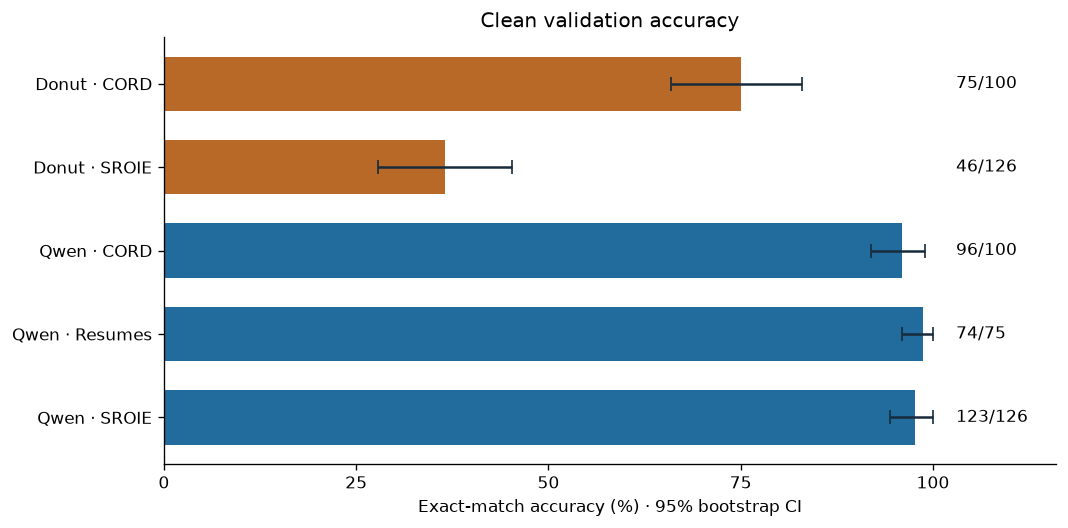

In [4]:
keys = ["model_key", "dataset_name", "task", "experiment_split"]
rng = np.random.default_rng(566)
rows = []
for key, group in df.groupby(keys, sort=True):
    values = group["clean_correct"].to_numpy(dtype=float)
    samples = rng.choice(values, size=(10000, len(values)), replace=True).mean(axis=1)
    low, high = np.quantile(samples, [0.025, 0.975])
    rows.append(dict(zip(keys, key)) | {"N": len(group), "Correct": int(values.sum()),
        "Accuracy (%)": 100 * values.mean(), "CI low (%)": 100 * low, "CI high (%)": 100 * high})
accuracy = pd.DataFrame(rows)
for group in summary["groups"]:
    row = accuracy.loc[accuracy.model_key.eq(group["model_key"]) & accuracy.dataset_name.eq(group["dataset_name"])].iloc[0]
    assert row["Correct"] == group["clean_correct"] and row["N"] == group["documents"]
display(accuracy.style.format({col: "{:.1f}" for col in ("Accuracy (%)", "CI low (%)", "CI high (%)")}))
fig, ax = plt.subplots(figsize=(9, 4.5))
positions = np.arange(len(accuracy))
ax.barh(positions, accuracy["Accuracy (%)"], color=[COLORS[m] for m in accuracy.model_key], height=.65)
ax.errorbar(accuracy["Accuracy (%)"], positions,
            xerr=np.array([accuracy["Accuracy (%)"] - accuracy["CI low (%)"], accuracy["CI high (%)"] - accuracy["Accuracy (%)"]]),
            fmt="none", ecolor="#172b3a", capsize=4)
ax.set_yticks(positions, [f"{m.title()} · {LABELS[d]}" for m, d in zip(accuracy.model_key, accuracy.dataset_name)])
for i, row in accuracy.iterrows():
    ax.text(103, i, f"{row['Correct']}/{row['N']}", va="center", fontsize=10)
ax.set(xlim=(0, 116), xlabel="Exact-match accuracy (%) · 95% bootstrap CI", title="Clean validation accuracy")
ax.set_xticks([0, 25, 50, 75, 100])
ax.invert_yaxis()
fig.tight_layout()
plt.show()


## 3. Failure accounting

`clean-incorrect` includes every record not scored correct. Its count overlaps parsing/inference failures. For a non-overlapping view, the chart separates **correct**, **parsed but incorrect**, **parse failure**, and **inference failure**; inference failures take precedence if both statuses are failed. A parse failure means an answer could not be normalized, not that the GPU job crashed.

,model_key,dataset_name,task,experiment_split,N,Clean correct,Clean correct (%),Clean incorrect,Clean incorrect (%),Parse failures,Parse failures (%),Inference failures,Inference failures (%)
0,donut,cord_v2,receipt_total,validation,100,75,75.00,25,25.00,2,2.00,0,0.0
1,donut,sroie,receipt_total,validation,126,46,36.51,80,63.49,18,14.29,0,0.0
2,qwen,cord_v2,receipt_total,validation,100,96,96.00,4,4.00,0,0.00,0,0.0
3,qwen,resume_parsing_vision,resume_highest_degree,validation,75,74,98.67,1,1.33,0,0.00,0,0.0
4,qwen,sroie,receipt_total,validation,126,123,97.62,3,2.38,1,0.79,0,0.0


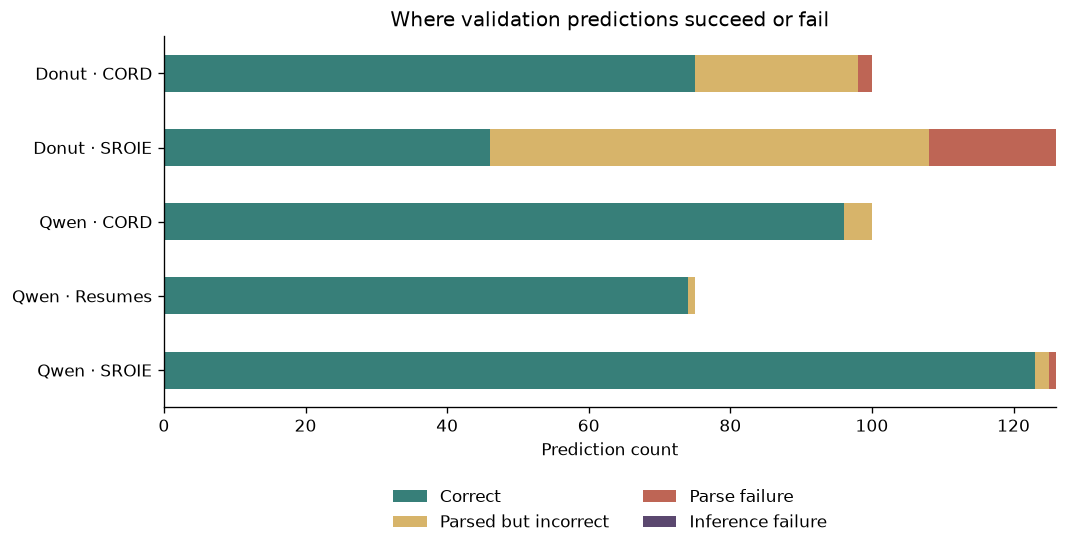

In [5]:
df["outcome"] = np.select(
    [df.status.eq("failed"), df.parse_status.eq("failed"), df.clean_correct],
    ["Inference failure", "Parse failure", "Correct"], default="Parsed but incorrect")
failure_rows = []
for key, group in df.groupby(keys):
    row = dict(zip(keys, key)) | {"N": len(group)}
    for label, mask in {"Clean correct": group.clean_correct,
                        "Clean incorrect": ~group.clean_correct,
                        "Parse failures": group.parse_status.eq("failed"),
                        "Inference failures": group.status.eq("failed")}.items():
        row[label] = int(mask.sum())
        row[label + " (%)"] = 100 * mask.mean()
    failure_rows.append(row)
failure_table = pd.DataFrame(failure_rows)
display(failure_table.round(2))
outcomes = pd.crosstab([df.model_key, df.dataset_name], df.outcome).reindex(
    columns=["Correct", "Parsed but incorrect", "Parse failure", "Inference failure"], fill_value=0)
ax = outcomes.plot.barh(stacked=True, figsize=(9, 4.8), color=["#377f79", "#d7b46a", "#be6555", "#5b486f"])
ax.set_yticklabels([f"{m.title()} · {LABELS[d]}" for m, d in outcomes.index])
ax.set(xlabel="Prediction count", ylabel="", title="Where validation predictions succeed or fail")
ax.invert_yaxis()
ax.legend(loc="upper center", bbox_to_anchor=(.5, -.18), ncol=2, frameon=False)
plt.tight_layout()
plt.show()


## 4. Runtime, memory, and determinism

Runtime is the **saved per-record inference measurement**, not queue wait or total job duration. Peak GPU memory is the saved model-run measurement and may repeat across records; it is not the entire device's reserved memory. These are descriptive measurements across workers, not a controlled hardware speed benchmark. Donut is receipt-only; Qwen's resume workload is different.

Production repeats only a subset of predictions for determinism. Missing `deterministic` values mean **not checked**, not failure. The separately reviewed smoke run repeated all 10 predictions successfully.

In [6]:
performance = df.groupby(keys).agg(
    N=("record_id", "size"), median_seconds=("runtime_seconds", "median"),
    p95_seconds=("runtime_seconds", lambda x: x.quantile(.95)),
    peak_gpu_memory_MB=("peak_gpu_memory_mb", "max")).reset_index()
display(performance.round(3))
determinism = df.assign(check=df.deterministic.map({True: "Passed", False: "Failed"}).fillna("Not checked"))
display(pd.crosstab(determinism.model_key, determinism.check))


,model_key,dataset_name,task,experiment_split,N,median_seconds,p95_seconds,peak_gpu_memory_MB
0,donut,cord_v2,receipt_total,validation,100,0.253,0.317,3498.0
1,donut,sroie,receipt_total,validation,126,0.263,0.377,3498.0
2,qwen,cord_v2,receipt_total,validation,100,0.265,0.417,7537.8
3,qwen,resume_parsing_vision,resume_highest_degree,validation,75,0.405,0.474,8038.6
4,qwen,sroie,receipt_total,validation,126,0.252,0.350,7541.2


check,Not checked,Passed
model_key,,
donut,221,5
qwen,296,5


## 5. Prediction examples and known evaluation limitations

Examples are selected deterministically by record ID, not randomly cherry-picked for favorable results. The correct-example table shows up to two records per model/dataset. The error table is capped at 20 rows, prioritizes parse/inference failures, and is not an exhaustive catalog.

**Confirmed negative-total limitation:** receipt `sroie/train/X51006556824` visibly states “Total Payable: -1.73.” Qwen returned `-1.73`, matching the saved target, but the frozen SROIE parser rejects negative amounts. Its saved score remains incorrect here. This is an evaluation limitation, not evidence that Qwen misread that receipt.

Other formatting cases include `25 000` for `25000` and hyphenated responses such as `367-10`. These remain scored under the original policy; the notebook does not repair answers using ground truth. Wrong fields such as dates and “gst summary” are also present. **No scores or candidate sets are corrected in this notebook.**

In [7]:
example_columns = ["model_key", "dataset_name", "record_id", "clean_target", "raw_response", "prediction_normalized", "parse_status", "clean_correct"]
correct_examples = df.loc[df.clean_correct].sort_values("record_id").groupby(["model_key", "dataset_name"]).head(2)
display(correct_examples[example_columns].reset_index(drop=True))
errors = df.loc[~df.clean_correct].copy()
errors["priority"] = np.where(errors.outcome.isin(["Parse failure", "Inference failure"]), 0, 1)
error_examples = errors.sort_values(["priority", "model_key", "dataset_name", "record_id"]).head(20)
display(error_examples[example_columns].reset_index(drop=True))
negative_case = df.loc[df.record_id.eq("sroie/train/X51006556824"), example_columns + ["attack_target", "attack_eligible"]]
display(Markdown("**Negative-total case (both model records):**"))
display(negative_case.reset_index(drop=True))


,model_key,dataset_name,record_id,clean_target,raw_response,prediction_normalized,parse_status,clean_correct
0,donut,cord_v2,cord_v2/validation/cord_v2-validation-0000,45500,"45,500",45500,ok,True
1,qwen,cord_v2,cord_v2/validation/cord_v2-validation-0000,45500,45500,45500,ok,True
2,donut,cord_v2,cord_v2/validation/cord_v2-validation-0001,23000,"23,000",23000,ok,True
3,qwen,cord_v2,cord_v2/validation/cord_v2-validation-0001,23000,23.000,23000,ok,True
4,qwen,resume_parsing_vision,resume_parsing_vision/validation/r00000,bachelor,bachelor,bachelor,ok,True
5,qwen,resume_parsing_vision,resume_parsing_vision/validation/r00014,bachelor,bachelor,bachelor,ok,True
6,donut,sroie,sroie/train/X00016469612,9.00,9.00,9.00,ok,True
7,qwen,sroie,sroie/train/X00016469612,9.00,9.00,9.00,ok,True
8,qwen,sroie,sroie/train/X00016469669,31.00,31.00,31.00,ok,True
9,donut,sroie,sroie/train/X51005337872,54.50,54.50,54.50,ok,True


,model_key,dataset_name,record_id,clean_target,raw_response,prediction_normalized,parse_status,clean_correct
0,donut,cord_v2,cord_v2/validation/cord_v2-validation-0069,174983,14:983,NaN,failed,False
1,donut,cord_v2,cord_v2/validation/cord_v2-validation-0080,25000,25 000,NaN,failed,False
2,donut,sroie,sroie/train/X51005268200,15.00,gst summary,NaN,failed,False
3,donut,sroie,sroie/train/X51005361946,37.10,14-03-18 21:49,NaN,failed,False
4,donut,sroie,sroie/train/X51005568899,5.90,15:16,NaN,failed,False
5,donut,sroie,sroie/train/X51005568911,37.80,08-03-17,NaN,failed,False
6,donut,sroie,sroie/train/X51005745190,367.10,367-10,NaN,failed,False
7,donut,sroie,sroie/train/X51005757235,31.00,09/03/2018 18:54,NaN,failed,False
8,donut,sroie,sroie/train/X51006008086,30.10,-2.98,NaN,failed,False
9,donut,sroie,sroie/train/X51006334741,20.05,************* gst summary************************,NaN,failed,False


**Negative-total case (both model records):**

,model_key,dataset_name,record_id,clean_target,raw_response,prediction_normalized,parse_status,clean_correct,attack_target,attack_eligible
0,donut,sroie,sroie/train/X51006556824,-1.73,6st,6.00,ok,False,-17.30,True
1,qwen,sroie,sroie/train/X51006556824,-1.73,-1.73,NaN,failed,False,-17.30,True


## 6. Candidates for adversarial attacks

A candidate must be **clean-correct AND attack-eligible**, with successful inference and parsing. Dataset eligibility alone does not imply baseline correctness. Saved clean-correct ID files include all correct examples; later stages must still apply eligibility, model/revision, prompt, and split filters.

These are candidate counts, not evidence of a successful attack. Receipt targets follow the existing ten-times-total rule. Negative and zero totals need a documented attack policy before attack execution; this notebook preserves their original eligibility and target values.

In [8]:
df["attack_candidate"] = df.clean_correct & df.attack_eligible & df.status.eq("complete") & df.parse_status.eq("ok")
candidates = df.groupby(keys).agg(
    documents=("record_id", "size"), dataset_eligible=("attack_eligible", "sum"),
    clean_correct=("clean_correct", "sum"), attack_candidates=("attack_candidate", "sum")).reset_index()
display(candidates)
receipt_candidates = df.loc[df.task.eq("receipt_total")].groupby("model_key").attack_candidate.sum()
display(receipt_candidates.rename("Receipt attack candidates").to_frame())
receipt_totals = pd.to_numeric(df.loc[df.task.eq("receipt_total"), "clean_target"], errors="raise")
special = df.loc[receipt_totals.index[receipt_totals.le(0)],
    ["model_key", "record_id", "clean_target", "attack_target", "clean_correct", "attack_eligible", "attack_candidate"]]
display(Markdown("**Non-positive receipt totals requiring attack-policy review:**"))
display(special.reset_index(drop=True))


,model_key,dataset_name,task,experiment_split,documents,dataset_eligible,clean_correct,attack_candidates
0,donut,cord_v2,receipt_total,validation,100,100,75,75
1,donut,sroie,receipt_total,validation,126,126,46,46
2,qwen,cord_v2,receipt_total,validation,100,100,96,96
3,qwen,resume_parsing_vision,resume_highest_degree,validation,75,75,74,74
4,qwen,sroie,receipt_total,validation,126,126,123,123


,Receipt attack candidates
model_key,
donut,121
qwen,219


**Non-positive receipt totals requiring attack-policy review:**

,model_key,record_id,clean_target,attack_target,clean_correct,attack_eligible,attack_candidate
0,donut,sroie/train/X51006556824,-1.73,-17.30,False,True,False
1,qwen,sroie/train/X51006556824,-1.73,-17.30,False,True,False


## 7. Findings and handoff

- All five workers contributed to the accepted validation baseline: **527 predictions on 301 documents**, with **zero inference failures**.
- Qwen scored **96/100 on CORD**, **123/126 on SROIE**, and **74/75 on resumes**. Donut scored **75/100 on CORD** and **46/126 on SROIE** under the unchanged normalization policy.
- There are **21 parsing failures** (20 Donut, one Qwen). These remain in the accuracy denominator, including the confirmed negative-total limitation.
- The receipt attack pools contain **121 Donut** and **219 Qwen** clean-correct eligible predictions under the saved policy. Resume results are a separate task and should not be pooled into receipt accuracy.
- These results establish validation clean performance. They do not establish held-out test generalization, adversarial success, or robustness.

**Next experiments:** review/freeze the Donut attack configuration, run a small attack smoke test on eligible clean-correct receipts, verify bounds and save/reload survival, and test checkpoint restart. Qwen attack optimization feasibility remains a separate Phase 1 milestone. Do not run the held-out test split until validation decisions are frozen.

The original merged artifacts remain authoritative for this run. This notebook neither writes corrected predictions nor modifies the data, parser, or attack configuration.